# DeepLabV3+ on PASCAL VOC 2012 — Semantic Segmentation

**Architecture:** DeepLabV3+ with ResNet-101 encoder  
**Dataset:** PASCAL VOC 2012 (21 classes, segmentation split)  
**Library:** [`segmentation-models-pytorch`](https://github.com/qubvel/segmentation_models.pytorch)

---

## 1. Imports

In [2]:
import copy
import random
from pathlib import Path

import albumentations as A
import cv2
import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import segmentation_models_pytorch as smp
from albumentations.pytorch import ToTensorV2
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from tqdm import tqdm

## 2. Configuration

In [18]:
# !ls ../input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val -la

total 424
drwxr-xr-x 7 nobody nogroup      0 Apr 12 22:00 .
drwxr-xr-x 3 nobody nogroup      0 Apr 12 21:57 ..
drwxr-xr-x 2 nobody nogroup      0 Apr 12 21:58 Annotations
-rw-r--r-- 1 nobody nogroup 433980 Apr 12 22:00 devkit_doc.pdf
drwxr-xr-x 6 nobody nogroup      0 Apr 12 21:58 ImageSets
drwxr-xr-x 2 nobody nogroup      0 Apr 12 22:00 JPEGImages
drwxr-xr-x 2 nobody nogroup      0 Apr 12 22:00 SegmentationClass
drwxr-xr-x 2 nobody nogroup      0 Apr 12 22:00 SegmentationObject


In [ ]:
# ── Paths ──────────────────────────────────────────────────────────────────────
DATA_ROOT       = Path("VOC2012_train_val")
# DATA_ROOT       = Path("../input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val")
CHECKPOINT_LAST = Path("last_model.pth")
CHECKPOINT_BEST = Path("best_model.pth")

# ── Model ──────────────────────────────────────────────────────────────────────
ENCODER         = "resnet101"
ENCODER_WEIGHTS = "imagenet"   # pretrained backbone weights
OUTPUT_STRIDE   = 16

# ── Training ───────────────────────────────────────────────────────────────────
IMAGE_SIZE              = 256
BATCH_SIZE              = 32
NUM_WORKERS             = 0    # set >0 on Linux/macOS for faster loading
LEARNING_RATE           = 1e-4
NUM_EPOCHS              = 50
EARLY_STOPPING_PATIENCE = 10
IGNORE_INDEX            = 255  # VOC boundary/void pixels

# ── Device ─────────────────────────────────────────────────────────────────────
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device : {DEVICE}")
print(f"Data   : {DATA_ROOT.resolve()}")

Device : cuda
Data   : /kaggle/input/datasets/gopalbhattrai/pascal-voc-2012-dataset/VOC2012_train_val/VOC2012_train_val


## 3. PASCAL VOC 2012 Dataset

In [29]:
# ── Class labels & colour palette (standard VOC) ───────────────────────────────
VOC_CLASSES = [
    "background", "aeroplane", "bicycle",  "bird",    "boat",
    "bottle",     "bus",       "car",      "cat",     "chair",
    "cow",        "diningtable", "dog",    "horse",   "motorbike",
    "person",     "potted plant", "sheep", "sofa",    "train",
    "tv/monitor",
]

NUM_CLASSES = len(VOC_CLASSES)  # 21

# RGB colours for each class (for visualisation only)
VOC_COLORMAP = np.array([
    [  0,   0,   0], [128,   0,   0], [  0, 128,   0], [128, 128,   0],
    [  0,   0, 128], [128,   0, 128], [  0, 128, 128], [128, 128, 128],
    [ 64,   0,   0], [192,   0,   0], [ 64, 128,   0], [192, 128,   0],
    [ 64,   0, 128], [192,   0, 128], [ 64, 128, 128], [192, 128, 128],
    [  0,  64,   0], [128,  64,   0], [  0, 192,   0], [128, 192,   0],
    [  0,  64, 128],
], dtype=np.uint8)


def decode_segmentation_mask(mask: np.ndarray) -> np.ndarray:
    """Map class-index mask (H, W) → RGB image (H, W, 3) for display."""
    h, w = mask.shape
    rgb = np.zeros((h, w, 3), dtype=np.uint8)
    for cls_idx, color in enumerate(VOC_COLORMAP):
        rgb[mask == cls_idx] = color
    return rgb


class PascalVOCDataset(Dataset):
    """
    PASCAL VOC 2012 Segmentation dataset.

    Expected directory layout (standard VOC structure):
        <root>/
            ImageSets/Segmentation/{train,val}.txt
            JPEGImages/<id>.jpg
            SegmentationClass/<id>.png   ← palette PNG; pixel value = class index
    """

    def __init__(self, root: Path, split: str = "train", transform=None):
        assert split in {"train", "val"}, f"split must be 'train' or 'val', got '{split}'"
        split_file = root / "ImageSets" / "Segmentation" / f"{split}.txt"
        self.ids      = split_file.read_text().strip().splitlines()
        self.root     = root
        self.transform = transform

    def __len__(self) -> int:
        return len(self.ids)

    def __getitem__(self, idx: int):
        name  = self.ids[idx]
        image = cv2.cvtColor(
            cv2.imread(str(self.root / "JPEGImages" / f"{name}.jpg")),
            cv2.COLOR_BGR2RGB,
        )
        # Read palette PNG directly — pixel value already encodes class index
        mask = np.array(Image.open(self.root / "SegmentationClass" / f"{name}.png"))

        if self.transform is not None:
            out   = self.transform(image=image, mask=mask)
            image = out["image"]
            mask  = out["mask"]

        return image, mask.long()

## 4. Data Transforms & Loaders

In [30]:
# ImageNet statistics match the pretrained encoder weights
_IMAGENET_MEAN = (0.485, 0.456, 0.406)
_IMAGENET_STD  = (0.229, 0.224, 0.225)

train_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.HorizontalFlip(p=0.5),
    A.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1, p=0.3),
    A.Normalize(mean=_IMAGENET_MEAN, std=_IMAGENET_STD),
    ToTensorV2(),
])

val_transform = A.Compose([
    A.Resize(IMAGE_SIZE, IMAGE_SIZE),
    A.Normalize(mean=_IMAGENET_MEAN, std=_IMAGENET_STD),
    ToTensorV2(),
])

train_dataset = PascalVOCDataset(DATA_ROOT, split="train", transform=train_transform)
val_dataset   = PascalVOCDataset(DATA_ROOT, split="val",   transform=val_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=True,
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=True,
)

print(f"Train samples : {len(train_dataset)}")
print(f"Val   samples : {len(val_dataset)}")

Train samples : 1464
Val   samples : 1449


## 5. Model

Using [`segmentation-models-pytorch`](https://github.com/qubvel/segmentation_models.pytorch) — available on PyPI, no local clone required.

In [31]:
model = smp.DeepLabV3Plus(
    encoder_name=ENCODER,
    encoder_weights=ENCODER_WEIGHTS,
    in_channels=3,
    classes=NUM_CLASSES,
    encoder_output_stride=OUTPUT_STRIDE,
).to(DEVICE)

optimizer = optim.Adam(model.parameters(), lr=LEARNING_RATE)
criterion = nn.CrossEntropyLoss(ignore_index=IGNORE_INDEX)

print(f"Model  : DeepLabV3+ / {ENCODER}")
n_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Params : {n_params:,}")

Model  : DeepLabV3+ / resnet101
Params : 45,674,853


## 6. Training Utilities

In [32]:
class EarlyStopping:
    """Stop training when validation loss stops improving."""

    def __init__(self, patience: int = 10, min_delta: float = 0.0, restore_best: bool = False):
        self.patience     = patience
        self.min_delta    = min_delta
        self.restore_best = restore_best
        self.best_weights = None
        self.best_loss    = float("inf")
        self.counter      = 0

    def step(self, model: nn.Module, val_loss: float) -> bool:
        """Returns True when training should stop."""
        if self.best_loss - val_loss > self.min_delta:
            self.best_loss    = val_loss
            self.best_weights = copy.deepcopy(model.state_dict())
            self.counter      = 0
        else:
            self.counter += 1
            if self.counter >= self.patience:
                if self.restore_best and self.best_weights is not None:
                    model.load_state_dict(self.best_weights)
                return True
        return False

    def __repr__(self) -> str:
        return f"EarlyStopping(patience={self.patience}, counter={self.counter}/{self.patience})"


def save_checkpoint(model: nn.Module, epoch: int, loss: float, path: Path) -> None:
    torch.save({"epoch": epoch, "model_state_dict": model.state_dict(), "loss": loss}, path)


def compute_miou(
    model: nn.Module,
    loader: DataLoader,
    num_classes: int,
    device: torch.device,
    ignore_index: int = 255,
) -> float:
    """Compute mean IoU over the full dataset split."""
    model.eval()
    intersection = torch.zeros(num_classes)
    union        = torch.zeros(num_classes)

    with torch.no_grad():
        for images, masks in loader:
            preds = model(images.to(device)).argmax(dim=1).cpu()  # (B, H, W)
            valid = masks != ignore_index
            for cls in range(num_classes):
                pred_cls   = (preds == cls) & valid
                target_cls = (masks == cls) & valid
                intersection[cls] += (pred_cls & target_cls).sum()
                union[cls]        += (pred_cls | target_cls).sum()

    iou_per_class = intersection / union.clamp(min=1)
    present       = union > 0
    return iou_per_class[present].mean().item()

## 7. Training Loop

In [33]:
def train(
    model: nn.Module,
    train_loader: DataLoader,
    val_loader: DataLoader,
    criterion: nn.Module,
    optimizer: optim.Optimizer,
    num_epochs: int,
    device: torch.device,
    early_stopping: EarlyStopping,
) -> None:
    best_val_loss = float("inf")

    for epoch in range(1, num_epochs + 1):
        # ── Train ──────────────────────────────────────────────────────────────
        model.train()
        train_loss = 0.0
        bar = tqdm(train_loader, desc=f"Epoch {epoch}/{num_epochs} [train]", colour="cyan")
        for images, masks in bar:
            images, masks = images.to(device), masks.to(device)
            optimizer.zero_grad()
            loss = criterion(model(images), masks)
            loss.backward()
            optimizer.step()
            train_loss += loss.item()
            bar.set_postfix(loss=f"{loss.item():.4f}")

        avg_train_loss = train_loss / len(train_loader)

        # ── Validate ───────────────────────────────────────────────────────────
        model.eval()
        val_loss = 0.0
        with torch.no_grad():
            for images, masks in val_loader:
                images, masks = images.to(device), masks.to(device)
                val_loss += criterion(model(images), masks).item()
        avg_val_loss = val_loss / len(val_loader)

        print(
            f"Epoch [{epoch:>3}/{num_epochs}]  "
            f"train_loss={avg_train_loss:.4f}  val_loss={avg_val_loss:.4f}  "
            f"{early_stopping}"
        )

        # ── Checkpointing ──────────────────────────────────────────────────────
        save_checkpoint(model, epoch, avg_val_loss, CHECKPOINT_LAST)
        if avg_val_loss < best_val_loss:
            best_val_loss = avg_val_loss
            save_checkpoint(model, epoch, avg_val_loss, CHECKPOINT_BEST)
            print(f"New best val_loss={best_val_loss:.4f} — checkpoint saved")

        if early_stopping.step(model, avg_val_loss):
            print(f"Early stopping triggered at epoch {epoch}.")
            break

In [34]:
early_stopping = EarlyStopping(patience=EARLY_STOPPING_PATIENCE, restore_best=True)

train(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    criterion=criterion,
    optimizer=optimizer,
    num_epochs=NUM_EPOCHS,
    device=DEVICE,
    early_stopping=early_stopping,
)

Epoch 1/50 [train]: 100%|██████████| 46/46 [00:59<00:00,  1.29s/it, loss=1.6379]


Epoch [  1/50]  train_loss=2.0930  val_loss=1.5999  EarlyStopping(patience=10, counter=0/10)
New best val_loss=1.5999 — checkpoint saved


Epoch 2/50 [train]: 100%|██████████| 46/46 [00:58<00:00,  1.27s/it, loss=1.0268]


Epoch [  2/50]  train_loss=1.1832  val_loss=0.9785  EarlyStopping(patience=10, counter=0/10)
New best val_loss=0.9785 — checkpoint saved


Epoch 3/50 [train]: 100%|██████████| 46/46 [00:58<00:00,  1.26s/it, loss=0.6253]


...

Epoch [ 21/50]  train_loss=0.0881  val_loss=0.3831  EarlyStopping(patience=10, counter=3/10)


Epoch 22/50 [train]: 100%|██████████| 46/46 [00:58<00:00,  1.26s/it, loss=0.1783]


Epoch [ 22/50]  train_loss=0.0947  val_loss=0.4498  EarlyStopping(patience=10, counter=4/10)


Epoch 23/50 [train]:   4%|▍         | 2/46 [00:03<01:24,  1.91s/it, loss=0.1045]


KeyboardInterrupt: 

## 8. Evaluation

In [35]:
# Load the best checkpoint
checkpoint = torch.load(CHECKPOINT_BEST, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint["model_state_dict"])
print(f"Loaded checkpoint from epoch {checkpoint['epoch']}  (val_loss={checkpoint['loss']:.4f})")

miou = compute_miou(model, val_loader, NUM_CLASSES, DEVICE, ignore_index=IGNORE_INDEX)
print(f"Validation mIoU : {miou:.4f}  ({miou * 100:.2f}%)")

Loaded checkpoint from epoch 17  (val_loss=0.3440)
Validation mIoU : 0.6413  (64.13%)


## 9. Visualisation — Predictions vs Ground Truth

Displaying indices: [414, 850, 972, 3, 172, 804]


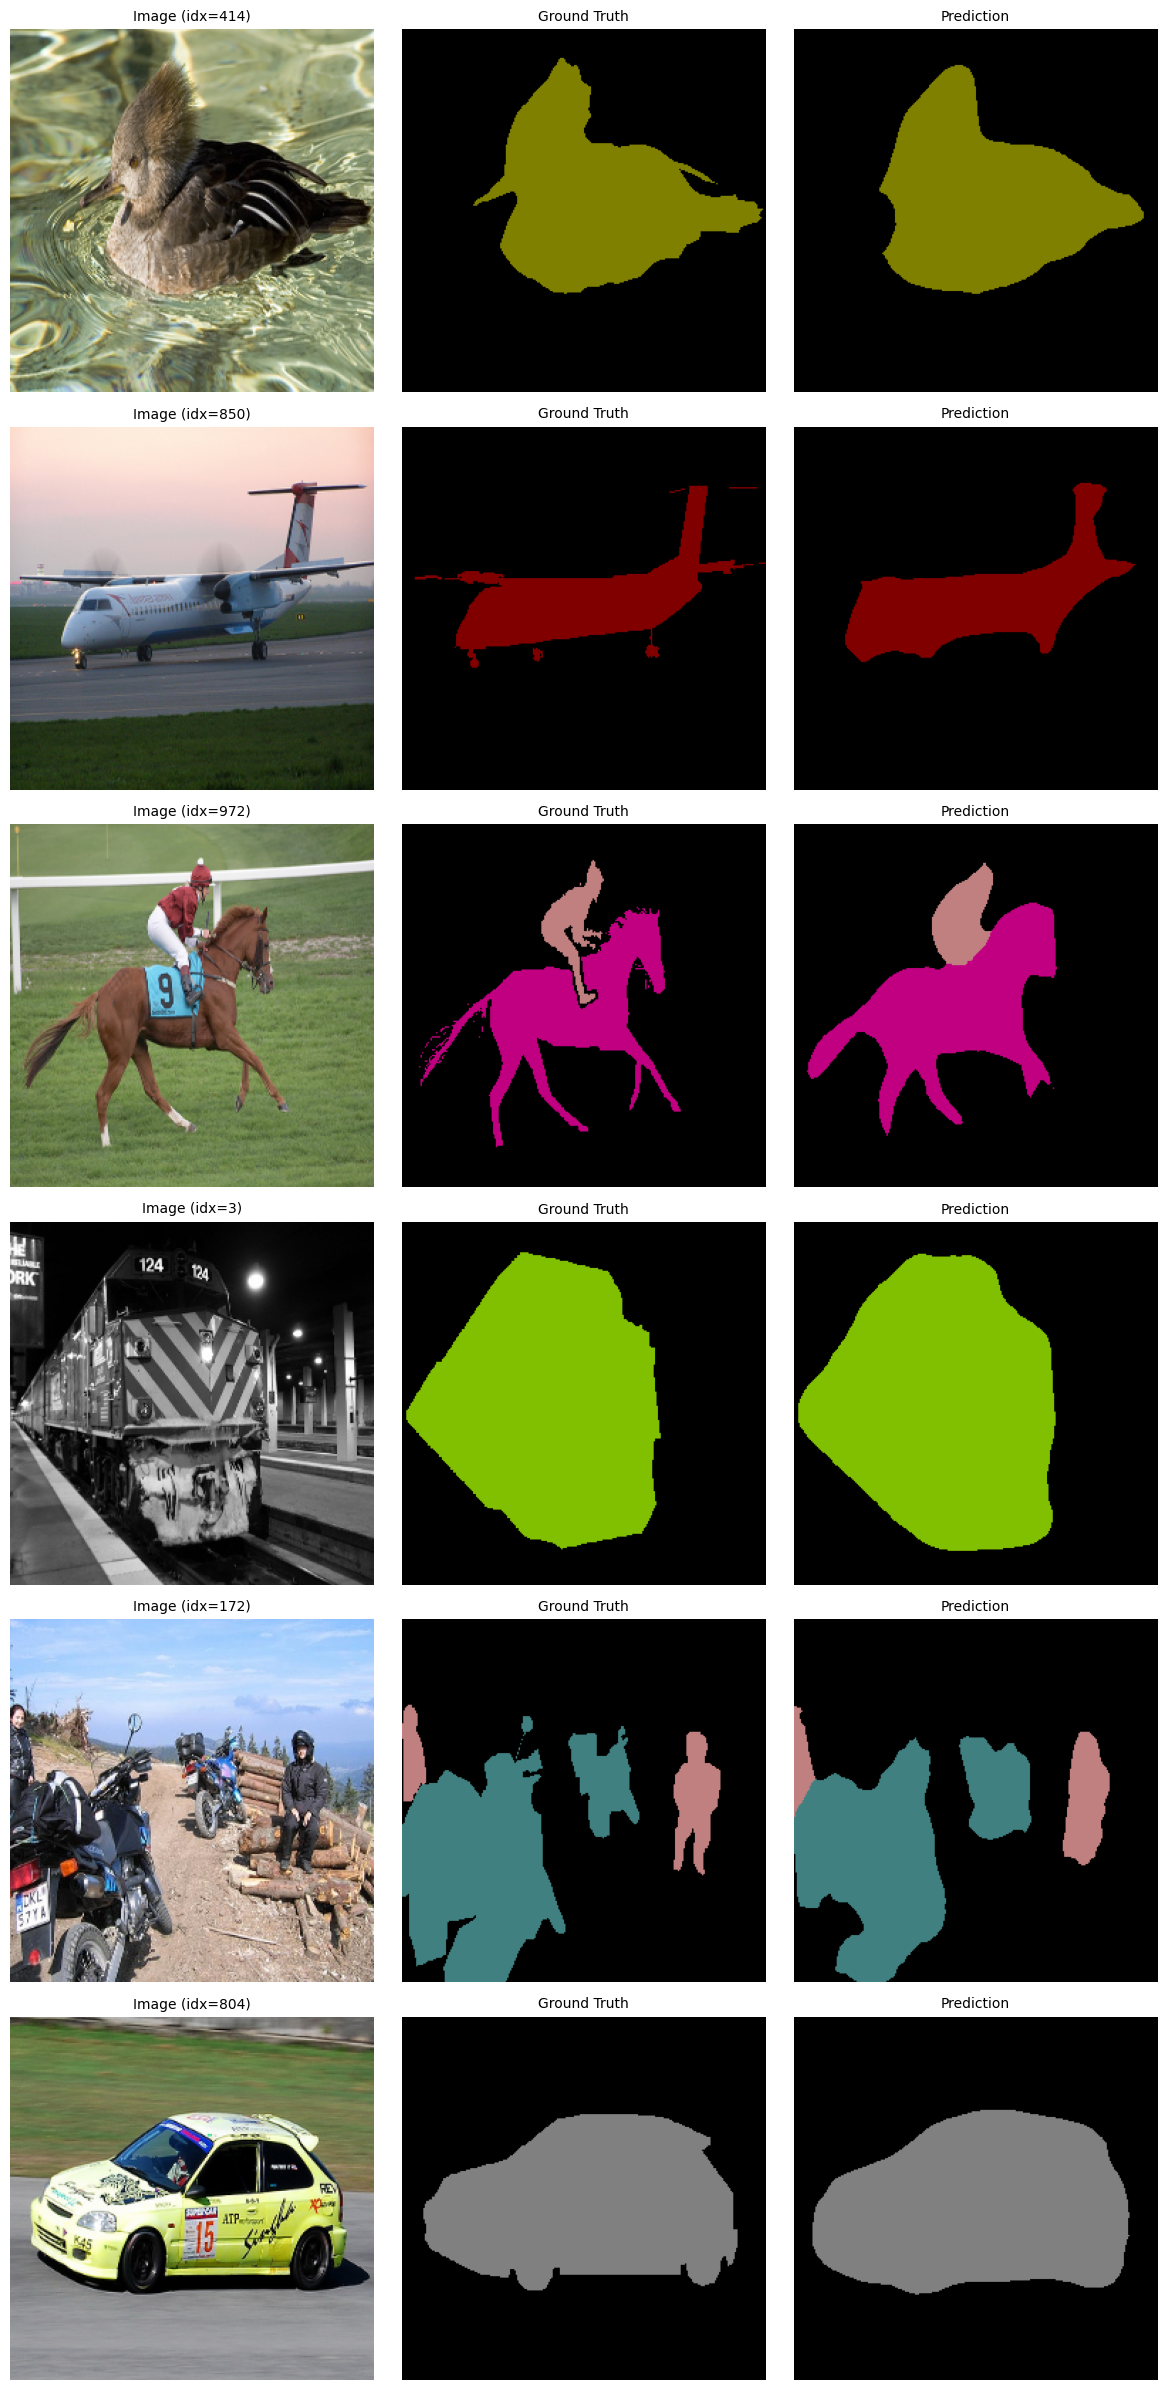

In [36]:
def visualize_predictions(
    model: nn.Module,
    dataset: Dataset,
    device: torch.device,
    indices: list[int] | None = None,
    n_random: int = 6,
    imagenet_mean: tuple = (0.485, 0.456, 0.406),
    imagenet_std:  tuple = (0.229, 0.224, 0.225),
) -> None:
    """Display original image, ground-truth mask, and predicted mask side-by-side."""
    if indices is None:
        indices = random.sample(range(len(dataset)), min(n_random, len(dataset)))
    print(f"Displaying indices: {indices}")

    mean = torch.tensor(imagenet_mean).view(3, 1, 1)
    std  = torch.tensor(imagenet_std).view(3, 1, 1)

    model.eval()
    fig, axes = plt.subplots(len(indices), 3, figsize=(12, 4 * len(indices)))
    if len(indices) == 1:
        axes = axes[np.newaxis, :]  # ensure 2-D indexing works for a single row

    with torch.no_grad():
        for row, idx in enumerate(indices):
            image_t, mask = dataset[idx]           # (C, H, W), (H, W)
            pred = model(image_t.unsqueeze(0).to(device)).argmax(dim=1).squeeze().cpu().numpy()

            # Undo normalisation for display
            image_display = (image_t * std + mean).permute(1, 2, 0).numpy().clip(0, 1)
            gt_display    = decode_segmentation_mask(mask.numpy())
            pred_display  = decode_segmentation_mask(pred)

            for ax, img, title in zip(
                axes[row],
                [image_display, gt_display, pred_display],
                [f"Image (idx={idx})", "Ground Truth", "Prediction"],
            ):
                ax.imshow(img)
                ax.set_title(title, fontsize=10)
                ax.axis("off")

    plt.tight_layout()
    plt.show()


visualize_predictions(model, val_dataset, DEVICE, n_random=6)